In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==============================================================================
# SEL 2: KOLEKSI KOMENTAR YOUTUBE RESMI & SENSOR PRIVASI
# ==============================================================================
!pip install -q google-api-python-client

import os
import re
import hashlib
import unicodedata
from datetime import datetime, timezone
import pandas as pd
from googleapiclient.discovery import build

# 1. PENGATURAN MODE KOLEKSI
AMBIL_DATA_BARU = False  # Ubah True jika ingin scraping baru dari YouTube, False jika pakai data yang sudah ada di Drive

# Isi jika AMBIL_DATA_BARU = True:
YOUTUBE_API_KEY = ""
HASH_SALT = "qris_surcharge_framing_research_salt_2024_secure_key"
TARGET_VIDEO_ID = "oV237Tpqzd4" # Contoh video kreator konsumen

# 2. FUNGSI STANDAR ETIKA & PRIVASI DATA (SHA-256 HASHING & REDAKSI)
def hash_id(identifier, salt):
    if not identifier: return ""
    return hashlib.sha256(f"{salt}:{identifier}".encode("utf-8")).hexdigest()

def protect_and_clean_text(text):
    if not isinstance(text, str): return ""
    text = unicodedata.normalize('NFKC', text)
    text = re.sub(r'[​‌‍⁠﻿]', '', text)                                      # Hapus zero-width
    text = re.sub(r'(?<![\w.])@\w[\w.\-]*', '@user', text)                  # Sensor mention
    text = re.sub(r'(?<![\w.+-])[\w.+-]+@[\w-]+(?:\.[\w-]+)+', '[email]', text) # Sensor email
    text = re.sub(r'(?<![\d+])(?:\+?62|0)8\d(?:[\s.-]?\d){6,10}(?!\d)', '[phone]', text) # Sensor no HP
    text = re.sub(r'(\D)\1{3,}', r'\1\1\1', text)                          # Ringkas karakter berulang
    return ' '.join(text.split())

# 3. EKSEKUSI PENGAMBILAN DATA
comments_file = os.path.join(folder_path, 'interim', 'comments.csv')

if AMBIL_DATA_BARU:
    print(f"Mengambil data komentar baru dari YouTube untuk Video ID: {TARGET_VIDEO_ID}...")
    youtube = build('youtube', 'v3', developerKey=YOUTUBE_API_KEY)
    collected = []

    req = youtube.commentThreads().list(
        part="snippet,replies", videoId=TARGET_VIDEO_ID, maxResults=100, textFormat="plainText"
    )
    while req and len(collected) < 150:
        res = req.execute()
        for item in res.get('items', []):
            top = item['snippet']['topLevelComment']['snippet']
            top_id = item['snippet']['topLevelComment']['id']
            author_ch = top.get('authorChannelId', {}).get('value', '')

            collected.append({
                'comment_hash': hash_id(top_id, HASH_SALT),
                'parent_hash': '',
                'author_hash': hash_id(author_ch, HASH_SALT),
                'video_id': TARGET_VIDEO_ID,
                'is_reply': 0,
                'text': protect_and_clean_text(top.get('textDisplay', '')),
                'published_at': top.get('publishedAt', ''),
                'like_count': top.get('likeCount', 0),
                'retrieved_at_utc': datetime.now(timezone.utc).isoformat()
            })
            if 'replies' in item:
                for rep in item['replies']['comments']:
                    r_snip = rep['snippet']
                    r_auth = r_snip.get('authorChannelId', {}).get('value', '')
                    collected.append({
                        'comment_hash': hash_id(rep['id'], HASH_SALT),
                        'parent_hash': hash_id(top_id, HASH_SALT),
                        'author_hash': hash_id(r_auth, HASH_SALT),
                        'video_id': TARGET_VIDEO_ID,
                        'is_reply': 1,
                        'text': protect_and_clean_text(r_snip.get('textDisplay', '')),
                        'published_at': r_snip.get('publishedAt', ''),
                        'like_count': r_snip.get('likeCount', 0),
                        'retrieved_at_utc': datetime.now(timezone.utc).isoformat()
                    })
        req = youtube.commentThreads().list_next(req, res)

    df_comments = pd.DataFrame(collected)
    print(f"Selesai! Berhasil mengambil {len(df_comments)} komentar baru.")
else:
    # Memakai dataset 7.557 komentar yang sudah ada di Drive
    print("Mode: Menggunakan dataset komentar yang sudah ada di Google Drive.")
    df_comments = pd.read_csv(comments_file)
    print(f"Total komentar termuat dari Drive: {len(df_comments):,} komentar.")

# Tampilkan 3 komentar teratas (dengan ID ter-hash dan teks tersensor)
display(df_comments[['comment_hash', 'text', 'like_count']].head(3))

Mode: Menggunakan dataset komentar yang sudah ada di Google Drive.
Total komentar termuat dari Drive: 7,557 komentar.


,comment_hash,text,like_count
0,b7aeaecd85744345eb721b12a809873bb3decf71832cce...,Bang karo untuk topup sama apa enggak?,0
1,ce9d6080355408484bd4981850c171a1c3637f671339f3...,Negara tertinggal. Sejak kuno pungli di setiap...,0
2,852a4d1343eb0cc7db3ad6918eee1ca12af387737d8783...,"biaya MDR sangat merugikan pelaku usaha, mendi...",0


In [3]:
import os
import pandas as pd
import cv2

# Definisi path folder di Drive
folder_path = '/content/drive/MyDrive/QRIS/qris-surcharge-framing'

# Cek daftar file di dalam folder
print(os.listdir(folder_path))

['README.md', 'indobert_run', 'annotation', 'indobert_run_before_20261110T150538Z', 'interim', 'raw', 'processed']


In [4]:
# 1. Instal library yang dibutuhkan
!pip install -q transformers scikit-learn

import random
import unicodedata
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

# Cek ketersediaan GPU (Sangat disarankan memakai T4 GPU di Colab)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device yang digunakan:', DEVICE)
if DEVICE.type == 'cuda':
    print('Nama GPU:', torch.cuda.get_device_name(0))
else:
    print('PERINGATAN: GPU tidak terdeteksi! Ubah runtime: Runtime > Change runtime type > T4 GPU')

Device yang digunakan: cuda
Nama GPU: NVIDIA L4


In [5]:
# 2. Konfigurasi Hyperparameter & Path Data
MODEL_NAME = 'indobenchmark/indobert-base-p1'
MODEL_LABEL = 'indobert_base_p1'
SEED = 20241021

# 7 Kode Framing Tematik (Multi-label)
LABELS = [
    'consumer_fairness',
    'merchant_cost',
    'regulatory_legitimacy',
    'responsibility',
    'trust',
    'remedy_proposal',
    'humor_cynicism',
]
MIN_POSITIVES = 15  # Ambang batas minimum sampel positif untuk dievaluasi
MAX_REPEAT_CHARS = 3

# Hyperparameter Pelatihan
MAX_LEN = 128
LEARNING_RATE = 2e-5
EPOCHS = 4
BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
VAL_FRACTION = 0.15
USE_POS_WEIGHT = True
THRESHOLD_GRID = [round(0.05 * step, 2) for step in range(1, 20)]

# Cari file dataset di folder annotation atau indobert_run
annotation_dir = os.path.join(folder_path, 'annotation')
if not os.path.exists(os.path.join(annotation_dir, 'colab_export.csv')):
    annotation_dir = os.path.join(folder_path, 'indobert_run')

export_path = os.path.join(annotation_dir, 'colab_export.csv')
folds_path = os.path.join(annotation_dir, 'folds.csv')

print(f"Menggunakan data dari: {annotation_dir}")
print(f"- colab_export: {os.path.exists(export_path)}")
print(f"- folds       : {os.path.exists(folds_path)}")

Menggunakan data dari: /content/drive/MyDrive/QRIS/qris-surcharge-framing/annotation
- colab_export: True
- folds       : True


In [6]:
# 3. Fungsi Pembersihan Teks & Pembacaan Data
ZERO_WIDTH = {chr(0x200B), chr(0x200C), chr(0x200D), chr(0x2060), chr(0xFEFF)}
TRUE_STRINGS = {'1', '1.0', 'yes', 'y', 'true', 't', 'ya', 'x'}

def collapse_repeats(text, max_repeat=MAX_REPEAT_CHARS):
    out = []
    for char in text:
        if not char.isdecimal() and len(out) >= max_repeat and all(prev == char for prev in out[-max_repeat:]):
            continue
        out.append(char)
    return ''.join(out)

def normalise_text(text):
    text = unicodedata.normalize('NFKC', str(text))
    text = ''.join(char for char in text if char not in ZERO_WIDTH)
    text = collapse_repeats(text)
    return ' '.join(text.split())

def to_binary(value):
    return int(str(value).strip().lower() in TRUE_STRINGS)

# Muat data kode komentar relevan
codes = pd.read_csv(export_path, dtype=str, keep_default_na=False, encoding='utf-8-sig')
codes = codes[codes['relevant'].str.strip().str.lower() == 'yes'].copy()
codes = codes.sort_values('comment_hash').reset_index(drop=True)
for label in LABELS:
    codes[label] = codes[label].map(to_binary)

# Muat partisi fold eksperimen
folds = pd.read_csv(folds_path, dtype={'comment_hash': str, 'group_id': str}, encoding='utf-8-sig')
folds['repeat'] = folds['repeat'].astype(int)
folds['fold'] = folds['fold'].astype(int)

if 'group_id' in folds.columns:
    group_of = dict(zip(folds['comment_hash'], folds['group_id']))
    GROUPS = codes['comment_hash'].map(group_of).to_numpy()
else:
    GROUPS = codes['thread_hash'].where(codes['thread_hash'] != '', codes['comment_hash']).to_numpy()

positives = codes[LABELS].sum()
KEPT_LABELS = [label for label in LABELS if positives[label] >= MIN_POSITIVES]
SKIPPED_LABELS = [label for label in LABELS if positives[label] < MIN_POSITIVES]

print('Jumlah sampel positif per label:')
print(positives.to_string())
print('\nLabel yang diproses:', KEPT_LABELS)
if SKIPPED_LABELS:
    print('Label yang dilewati (< 15 positif):', SKIPPED_LABELS)

texts = [normalise_text(text) for text in codes['text']]
Y = codes[KEPT_LABELS].to_numpy(dtype=np.float32)
REPEATS = sorted(folds['repeat'].unique())
FOLDS = sorted(folds['fold'].unique())

print(f"\nTotal: {len(texts)} komentar relevan | {len(set(GROUPS))} grup thread | {len(REPEATS)} repeat x {len(FOLDS)} fold")

Jumlah sampel positif per label:
consumer_fairness         48
merchant_cost            126
regulatory_legitimacy     73
responsibility           150
trust                     14
remedy_proposal          141
humor_cynicism            92

Label yang diproses: ['consumer_fairness', 'merchant_cost', 'regulatory_legitimacy', 'responsibility', 'remedy_proposal', 'humor_cynicism']
Label yang dilewati (< 15 positif): ['trust']

Total: 605 komentar relevan | 480 grup thread | 3 repeat x 5 fold


In [7]:
# 4. Tokenizer IndoBERT & Dataset Loader
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class CommentDataset(Dataset):
    def __init__(self, indices):
        self.encodings = tokenizer([texts[i] for i in indices], truncation=True, padding='max_length', max_length=MAX_LEN)
        self.labels = Y[indices]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(values[idx]) for key, values in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.float32)
        return item

def make_loader(indices, shuffle, seed):
    generator = torch.Generator()
    generator.manual_seed(int(seed))
    return DataLoader(CommentDataset(indices), batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

def safe_ratio(num, den, zero_value=0.0):
    return float(num) / float(den) if den > 0 else zero_value

def nanmean(values):
    valid = [v for v in values if not np.isnan(v)]
    return float(np.mean(valid)) if valid else float('nan')

def fold_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int).reshape(len(y_true), -1)
    y_pred = np.asarray(y_pred, dtype=int).reshape(y_true.shape)
    tp = ((y_true == 1) & (y_pred == 1)).sum(axis=0)
    fp = ((y_true == 0) & (y_pred == 1)).sum(axis=0)
    fn = ((y_true == 1) & (y_pred == 0)).sum(axis=0)
    support = tp + fn
    n_labels = len(KEPT_LABELS)
    precision = [safe_ratio(tp[j], tp[j] + fp[j]) for j in range(n_labels)]
    recall = [safe_ratio(tp[j], support[j]) if support[j] > 0 else float('nan') for j in range(n_labels)]
    f1 = [safe_ratio(2 * tp[j], 2 * tp[j] + fp[j] + fn[j]) if support[j] > 0 else float('nan') for j in range(n_labels)]

    rows = []
    for j, label in enumerate(KEPT_LABELS):
        rows += [
            (label, 'precision', precision[j]),
            (label, 'recall', recall[j]),
            (label, 'f1', f1[j]),
            (label, 'support', float(support[j])),
        ]
    total_tp, total_fp, total_fn = tp.sum(), fp.sum(), fn.sum()
    valid = [j for j in range(n_labels) if support[j] > 0]
    rows += [
        ('overall', 'micro_precision', safe_ratio(total_tp, total_tp + total_fp)),
        ('overall', 'micro_recall', safe_ratio(total_tp, total_tp + total_fn)),
        ('overall', 'micro_f1', safe_ratio(2 * total_tp, 2 * total_tp + total_fp + total_fn)),
        ('overall', 'macro_precision', nanmean([precision[j] for j in valid])),
        ('overall', 'macro_recall', nanmean([recall[j] for j in valid])),
        ('overall', 'macro_f1', nanmean([f1[j] for j in valid])),
    ]
    row_tp = ((y_true == 1) & (y_pred == 1)).sum(axis=1)
    row_errors = (y_true != y_pred).sum(axis=1)
    samples_f1 = [safe_ratio(2 * t, 2 * t + e, zero_value=1.0) for t, e in zip(row_tp, row_errors)]
    rows.append(('overall', 'samples_f1', float(np.mean(samples_f1))))
    rows.append(('overall', 'hamming_loss', float((y_true != y_pred).mean())))
    return rows

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [8]:
# 5. Fungsi Pelatihan Model & Optimasi Ambang Batas
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def inner_validation_split(train_idx, rng):
    train_groups = GROUPS[train_idx]
    counts = pd.Series(train_groups).value_counts()
    target = max(1, int(round(VAL_FRACTION * len(train_idx))))
    chosen, size = set(), 0
    for group in rng.permutation(np.unique(train_groups)):
        if size >= target:
            break
        chosen.add(group)
        size += int(counts[group])
    in_val = np.array([g in chosen for g in train_groups])
    return train_idx[~in_val], train_idx[in_val]

def predict_proba(model, indices, seed):
    model.eval()
    outputs = []
    with torch.no_grad():
        for batch in make_loader(indices, shuffle=False, seed=seed):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            batch.pop('labels')
            outputs.append(torch.sigmoid(model(**batch).logits).cpu().numpy())
    return np.vstack(outputs)

def train_model(train_indices, seed):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(KEPT_LABELS), problem_type='multi_label_classification'
    )
    model.to(DEVICE)
    loader = make_loader(train_indices, shuffle=True, seed=seed)

    pos_weight = None
    if USE_POS_WEIGHT:
        y_train = Y[train_indices]
        pos_train = y_train.sum(axis=0)
        neg_train = len(y_train) - pos_train
        weights = np.where(pos_train > 0, neg_train / np.maximum(pos_train, 1.0), 1.0)
        pos_weight = torch.tensor(weights, dtype=torch.float32, device=DEVICE)

    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_steps = len(loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = batch.pop('labels')
            optimizer.zero_grad()
            loss = loss_fn(model(**batch).logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            running_loss += loss.item()
        print(f'    Epoch {epoch + 1}/{EPOCHS} - Training loss: {running_loss / max(len(loader), 1):.4f}')
    return model

def tune_thresholds(y_true, proba):
    thresholds = []
    for j in range(y_true.shape[1]):
        if y_true[:, j].sum() == 0:
            thresholds.append(0.5)
            continue
        best_t, best_f1 = 0.5, -1.0
        for t in THRESHOLD_GRID:
            pred = (proba[:, j] >= t).astype(int)
            tp = int(((pred == 1) & (y_true[:, j] == 1)).sum())
            errors = int((pred != y_true[:, j]).sum())
            f1 = safe_ratio(2 * tp, 2 * tp + errors)
            if f1 > best_f1 + 1e-12 or (abs(f1 - best_f1) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)):
                best_t, best_f1 = t, f1
        thresholds.append(best_t)
    return np.array(thresholds)

In [9]:
# 6. Eksekusi Pelatihan Cross-Validation
# Catatan: Bila ingin tes cepat (1 ulangan x 5 fold), ubah REPEATS_TO_RUN = [REPEATS[0]]
# Untuk replikasi naskah lengkap (3 ulangan x 5 fold = 15 runs, ~15-20 menit), gunakan REPEATS_TO_RUN = REPEATS
REPEATS_TO_RUN = REPEATS

records = []
thresholds_log = []

print(f"Memulai Cross-Validation IndoBERT ({len(REPEATS_TO_RUN)} repeat x {len(FOLDS)} fold)...")

for repeat in REPEATS_TO_RUN:
    fold_table = folds[folds['repeat'] == repeat]
    fold_of = dict(zip(fold_table['comment_hash'], fold_table['fold']))
    fold_array = np.array([fold_of[h] for h in codes['comment_hash']])

    for fold in FOLDS:
        run_seed = SEED + 100 * int(repeat) + int(fold)
        test_idx = np.where(fold_array == fold)[0]
        train_full = np.where(fold_array != fold)[0]
        inner_train, val_idx = inner_validation_split(train_full, np.random.default_rng(run_seed))

        print(f"\n[Repeat {repeat}, Fold {fold}] Train: {len(inner_train)}, Val: {len(val_idx)}, Test: {len(test_idx)}")
        model = train_model(inner_train, run_seed)

        # Tuning ambang batas pada set validasi internal
        val_proba = predict_proba(model, val_idx, run_seed)
        thresholds = tune_thresholds(Y[val_idx].astype(int), val_proba)

        # Evaluasi pada fold uji
        test_proba = predict_proba(model, test_idx, run_seed)
        y_pred = (test_proba >= thresholds).astype(int)

        for label, metric, value in fold_metrics(Y[test_idx].astype(int), y_pred):
            records.append({
                'model': MODEL_LABEL,
                'repeat': int(repeat),
                'fold': int(fold),
                'label': label,
                'metric': metric,
                'value': float(value),
            })

        thresholds_log.append({'repeat': int(repeat), 'fold': int(fold), **dict(zip(KEPT_LABELS, thresholds.tolist()))})

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("\nPelatihan selesai!")

Memulai Cross-Validation IndoBERT (3 repeat x 5 fold)...

[Repeat 0, Fold 0] Train: 411, Val: 73, Test: 121


[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (55 outputs left out)

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    Epoch 1/4 - Training loss: 1.1274
    Epoch 2/4 - Training loss: 0.9710
    Epoch 3/4 - Training loss: 0.8377
    Epoch 4/4 - Training loss: 0.7413

Pelatihan selesai!


In [10]:
# 7. Ringkasan Metrik (Sesuai Tabel VII & VIII di Naskah Jurnal)
fold_results = pd.DataFrame(records)

summary = (
    fold_results.groupby(['model', 'label', 'metric'], sort=False)['value']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .rename(columns={'std': 'sd', 'count': 'n_valid_folds'})
)
summary[['mean', 'sd']] = summary[['mean', 'sd']].round(4)

print("=== PERFORMA KESELURUHAN (Table VII Naskah) ===")
overall_df = summary[summary['label'] == 'overall'].copy()
display(overall_df)

print("\n=== PER-CODE F1 SCORE (Table VIII Naskah) ===")
per_code_f1 = summary[(summary['metric'] == 'f1') & (summary['label'] != 'overall')].copy()
display(per_code_f1[['label', 'mean', 'sd', 'n_valid_folds']])

# Simpan hasil CSV langsung ke folder Google Drive Anda
output_dir = os.path.join(folder_path, 'outputs')
os.makedirs(output_dir, exist_ok=True)

out_summary = os.path.join(output_dir, 'classifier_indobert.csv')
out_folds = os.path.join(output_dir, 'classifier_indobert_folds.csv')
out_thresholds = os.path.join(output_dir, 'indobert_thresholds.csv')

summary.to_csv(out_summary, index=False, encoding='utf-8-sig')
fold_results.to_csv(out_folds, index=False, encoding='utf-8-sig')
pd.DataFrame(thresholds_log).to_csv(out_thresholds, index=False, encoding='utf-8-sig')

print(f"\nSemua file hasil berhasil disimpan ke Google Drive Anda di folder: {output_dir}")

=== PERFORMA KESELURUHAN (Table VII Naskah) ===


,model,label,metric,mean,sd,n_valid_folds
24,indobert_base_p1,overall,micro_precision,0.3571,0.0449,15
25,indobert_base_p1,overall,micro_recall,0.6285,0.0606,15
26,indobert_base_p1,overall,micro_f1,0.4522,0.0328,15
27,indobert_base_p1,overall,macro_precision,0.3815,0.0675,15
28,indobert_base_p1,overall,macro_recall,0.6001,0.0483,15
29,indobert_base_p1,overall,macro_f1,0.4293,0.0297,15
30,indobert_base_p1,overall,samples_f1,0.4300,0.0558,15
31,indobert_base_p1,overall,hamming_loss,0.2662,0.0397,15



=== PER-CODE F1 SCORE (Table VIII Naskah) ===


,label,mean,sd,n_valid_folds
2,consumer_fairness,0.2572,0.1467,15
6,merchant_cost,0.5342,0.0727,15
10,regulatory_legitimacy,0.3633,0.0998,15
14,responsibility,0.4733,0.0516,15
18,remedy_proposal,0.5049,0.0636,15
22,humor_cynicism,0.4429,0.0997,15



Semua file hasil berhasil disimpan ke Google Drive Anda di folder: /content/drive/MyDrive/QRIS/qris-surcharge-framing/outputs


In [11]:
# 8. Pelatihan Supervised Baseline Classifiers (TF-IDF + LogReg + LinearSVC)
import time
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

# Definisi Fitur TF-IDF (Word n-gram 1-2 & Character n-gram 3-5)
TOKEN_PATTERN = r'\d+(?:[.,]\d+)*%?|[^\W\d_]+(?:-[^\W\d_]+)*'
PROBA_GRID = np.round(np.arange(1, 20) * 0.05, 2)
PERCENTILE_GRID = np.arange(5, 100, 5)

def build_features():
    return FeatureUnion([
        ('word', TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=2, max_df=1.0, sublinear_tf=True, token_pattern=TOKEN_PATTERN)),
        ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, max_df=1.0, sublinear_tf=True)),
    ])

def build_baseline_model(name, seed):
    if name == 'dummy_most_frequent':
        return DummyClassifier(strategy='most_frequent')
    if name == 'dummy_stratified':
        return DummyClassifier(strategy='stratified', random_state=seed)
    if name == 'logreg_ovr':
        clf = LogisticRegression(C=1.0, class_weight='balanced', solver='liblinear', max_iter=2000)
        return Pipeline([('features', build_features()), ('clf', OneVsRestClassifier(clf))])
    if name == 'linear_svc_ovr':
        clf = LinearSVC(C=1.0, class_weight='balanced', dual='auto', max_iter=5000)
        return Pipeline([('features', build_features()), ('clf', OneVsRestClassifier(clf))])
    raise ValueError(f"Model tidak dikenal: {name}")

def get_label_scores(model, texts_input, n_labels, kind):
    if kind == 'proba':
        scores = np.asarray(model.predict_proba(texts_input), dtype=float)
        if n_labels == 1 and scores.ndim == 2 and scores.shape[1] == 2:
            scores = scores[:, 1]
    else:
        scores = np.asarray(model.decision_function(texts_input), dtype=float)
    return scores.reshape(len(texts_input), -1)

def tune_baseline_thresholds(y_val, scores, kind):
    default = 0.5 if kind == 'proba' else 0.0
    grid = PROBA_GRID if kind == 'proba' else np.unique(np.percentile(scores, PERCENTILE_GRID))
    thresholds = []
    for j in range(y_val.shape[1]):
        truth = y_val[:, j]
        if truth.sum() == 0:
            thresholds.append(default)
            continue
        best_t, best_f1 = default, -1.0
        for t in grid:
            pred = (scores[:, j] >= t).astype(int)
            tp = int(((pred == 1) & (truth == 1)).sum())
            errors = int((pred != truth).sum())
            f1 = safe_ratio(2 * tp, 2 * tp + errors)
            closer = abs(t - default) < abs(best_t - default)
            if f1 > best_f1 + 1e-12 or (abs(f1 - best_f1) <= 1e-12 and closer):
                best_t, best_f1 = float(t), f1
        thresholds.append(best_t)
    return np.array(thresholds)

BASELINE_MODELS = ['dummy_most_frequent', 'dummy_stratified', 'logreg_ovr', 'linear_svc_ovr']
SCORE_KINDS = {'logreg_ovr': 'proba', 'linear_svc_ovr': 'decision'}

baseline_records = []
texts_array = np.array(texts)
started = time.time()
print("Memulai evaluasi baseline (Dummy, LogReg, LinearSVC)...")

for repeat in REPEATS:
    fold_table = folds[folds['repeat'] == repeat]
    fold_of = dict(zip(fold_table['comment_hash'], fold_table['fold']))
    fold_array = np.array([fold_of[h] for h in codes['comment_hash']])

    for fold in FOLDS:
        run_seed = SEED + 100 * int(repeat) + int(fold)
        test_idx = np.where(fold_array == fold)[0]
        train_full = np.where(fold_array != fold)[0]
        rng = np.random.default_rng(run_seed)
        inner_train, val_idx = inner_validation_split(train_full, rng)

        for name in BASELINE_MODELS:
            model = build_baseline_model(name, run_seed)
            tuning_setting = 'inner_validation_f1'

            if name.startswith('dummy'):
                model.fit(np.zeros((len(train_full), 1)), Y[train_full].astype(int))
                y_pred = model.predict(np.zeros((len(test_idx), 1)))
                tuning_setting = 'none'
            else:
                # Latih pada inner-train
                model.fit(texts_array[inner_train], Y[inner_train].astype(int))
                kind = SCORE_KINDS[name]

                # Tuning threshold pada set validasi
                val_scores = get_label_scores(model, texts_array[val_idx], len(KEPT_LABELS), kind)
                thresholds = tune_baseline_thresholds(Y[val_idx].astype(int), val_scores, kind)

                # Prediksi pada set tes
                test_scores = get_label_scores(model, texts_array[test_idx], len(KEPT_LABELS), kind)
                y_pred = (test_scores >= thresholds).astype(int)

            for label, metric, value in fold_metrics(Y[test_idx].astype(int), y_pred):
                baseline_records.append({
                    'model': name,
                    'repeat': int(repeat),
                    'fold': int(fold),
                    'label': label,
                    'metric': metric,
                    'value': float(value),
                    'threshold_tuning': tuning_setting
                })

print(f"Baseline selesai dalam {time.time() - started:.1f} detik!")

baseline_df = pd.DataFrame(baseline_records)
summary_baseline = (
    baseline_df.groupby(['model', 'label', 'metric'], sort=False)['value']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .rename(columns={'std': 'sd', 'count': 'n_valid_folds'})
)
summary_baseline[['mean', 'sd']] = summary_baseline[['mean', 'sd']].round(4)

# Simpan hasil baseline ke Google Drive
out_base_summary = os.path.join(output_dir, 'classifier_baseline.csv')
out_base_folds = os.path.join(output_dir, 'classifier_baseline_folds.csv')
summary_baseline.to_csv(out_base_summary, index=False, encoding='utf-8-sig')
baseline_df.to_csv(out_base_folds, index=False, encoding='utf-8-sig')
print(f"Hasil baseline tersimpan di: {out_base_summary}")

Memulai evaluasi baseline (Dummy, LogReg, LinearSVC)...
Baseline selesai dalam 7.7 detik!
Hasil baseline tersimpan di: /content/drive/MyDrive/QRIS/qris-surcharge-framing/outputs/classifier_baseline.csv


In [12]:
# 9. Tabel Perbandingan Lengkap: Baseline vs IndoBERT
all_classifiers = pd.concat([summary_baseline, summary], ignore_index=True)

# Urutan model sesuai naskah jurnal
MODEL_ORDER = ['dummy_most_frequent', 'dummy_stratified', 'logreg_ovr', 'linear_svc_ovr', 'indobert_base_p1']

print("=" * 70)
print("TABEL VII: PERBANDINGAN PERFORMA KESELURUHAN (OVERALL PERFORMANCE)")
print("=" * 70)

overall_table = []
for model in MODEL_ORDER:
    m_f1 = all_classifiers[(all_classifiers['model'] == model) & (all_classifiers['label'] == 'overall') & (all_classifiers['metric'] == 'micro_f1')]['mean'].values[0]
    M_f1 = all_classifiers[(all_classifiers['model'] == model) & (all_classifiers['label'] == 'overall') & (all_classifiers['metric'] == 'macro_f1')]['mean'].values[0]
    h_loss = all_classifiers[(all_classifiers['model'] == model) & (all_classifiers['label'] == 'overall') & (all_classifiers['metric'] == 'hamming_loss')]['mean'].values[0]
    s_f1 = all_classifiers[(all_classifiers['model'] == model) & (all_classifiers['label'] == 'overall') & (all_classifiers['metric'] == 'samples_f1')]['mean'].values[0]

    overall_table.append({
        'Model': model,
        'Micro F1': round(m_f1, 4),
        'Macro F1': round(M_f1, 4),
        'Samples F1': round(s_f1, 4),
        'Hamming Loss': round(h_loss, 4),
    })

df_table_vii = pd.DataFrame(overall_table)
display(df_table_vii)

print("\n" + "=" * 70)
print("TABEL VIII: PERBANDINGAN F1 SCORE PER KODE FRAMING (PER-CODE F1 MEAN)")
print("=" * 70)

per_code = all_classifiers[(all_classifiers['metric'] == 'f1') & (all_classifiers['label'] != 'overall')].copy()
table_viii = per_code.pivot(index='label', columns='model', values='mean')[MODEL_ORDER[1:]] # exclude dummy_most_frequent yang semuanya 0
display(table_viii.round(4))

TABEL VII: PERBANDINGAN PERFORMA KESELURUHAN (OVERALL PERFORMANCE)


,Model,Micro F1,Macro F1,Samples F1,Hamming Loss
0,dummy_most_frequent,0.0000,0.0000,0.3405,0.1736
1,dummy_stratified,0.2149,0.1913,0.2380,0.2756
2,logreg_ovr,0.4405,0.4333,0.3982,0.2568
3,linear_svc_ovr,0.4382,0.4157,0.4003,0.2469
4,indobert_base_p1,0.4522,0.4293,0.4300,0.2662



TABEL VIII: PERBANDINGAN F1 SCORE PER KODE FRAMING (PER-CODE F1 MEAN)


model,dummy_stratified,logreg_ovr,linear_svc_ovr,indobert_base_p1
label,,,,
consumer_fairness,0.1229,0.2826,0.2372,0.2572
humor_cynicism,0.1752,0.3195,0.2792,0.4429
merchant_cost,0.2099,0.5924,0.5830,0.5342
regulatory_legitimacy,0.1188,0.4215,0.4175,0.3633
remedy_proposal,0.2384,0.4948,0.5060,0.5049
responsibility,0.2827,0.4889,0.4713,0.4733


In [13]:
# 10. Evaluasi Kesepakatan Antarkoder (Reliability) & Alur Korpus
import math
from collections import Counter
from itertools import permutations

tables_dir = os.path.join(folder_path, 'outputs', 'tables')
figures_dir = os.path.join(folder_path, 'outputs', 'figures')
os.makedirs(tables_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

# Fungsi Metrik Reliabilitas Mandiri (Cohen's Kappa & Krippendorff's Alpha)
def _is_missing(val):
    if val is None or val is pd.NA:
        return True
    if isinstance(val, float) and math.isnan(val):
        return True
    return isinstance(val, str) and val.strip() == ""

def cohen_kappa(a, b):
    pairs = [(x, y) for x, y in zip(a, b) if not _is_missing(x) and not _is_missing(y)]
    n = len(pairs)
    if n == 0: return float("nan")
    observed = sum(x == y for x, y in pairs) / n
    ca, cb = Counter(x for x, _ in pairs), Counter(y for _, y in pairs)
    exp_num = sum(ca[c] * cb[c] for c in set(ca) | set(cb))
    if exp_num == n * n: return float("nan")
    expected = exp_num / (n * n)
    return (observed - expected) / (1 - expected)

def krippendorff_alpha_nominal(units):
    coincidences = Counter()
    for unit in units:
        values = [v for v in unit if not _is_missing(v)]
        m = len(values)
        if m < 2: continue
        for i, j in permutations(range(m), 2):
            coincidences[(values[i], values[j])] += 1.0 / (m - 1)
    marginals = Counter()
    for (c, _), weight in coincidences.items():
        marginals[c] += weight
    n = sum(marginals.values())
    if n <= 1: return float("nan")
    obs_dis = sum(w for (c, k), w in coincidences.items() if c != k)
    exp_pairs = sum(marginals[c] * marginals[k] for c in marginals for k in marginals if c != k)
    if exp_pairs == 0: return float("nan")
    return 1.0 - (n - 1) * obs_dis / exp_pairs

def percent_agreement(a, b):
    pairs = [(x, y) for x, y in zip(a, b) if not _is_missing(x) and not _is_missing(y)]
    return sum(x == y for x, y in pairs) / len(pairs) if pairs else float("nan")

# Muat data coder1 dan coder2
coder1_path = os.path.join(folder_path, 'annotation', 'coder_coder1.csv')
coder2_path = os.path.join(folder_path, 'annotation', 'coder_coder2.csv')
rel_subset_path = os.path.join(folder_path, 'annotation', 'reliability_subset.csv')

c1 = pd.read_csv(coder1_path, dtype=str).fillna('')
c2 = pd.read_csv(coder2_path, dtype=str).fillna('')
rel_hashes = set(pd.read_csv(rel_subset_path, dtype=str)['comment_hash'])

c1 = c1[c1['comment_hash'].isin(rel_hashes)].sort_values('comment_hash').reset_index(drop=True)
c2 = c2[c2['comment_hash'].isin(rel_hashes)].sort_values('comment_hash').reset_index(drop=True)

ENTMAN_FUNCS = ['problem_definition', 'causal_attribution', 'moral_evaluation', 'remedy']
THEMATIC_VARS = ['consumer_fairness', 'merchant_cost', 'regulatory_legitimacy', 'responsibility', 'trust', 'remedy_proposal', 'humor_cynicism']
RESP_TARGETS = ['responsibility_target_merchant', 'responsibility_target_payment_provider', 'responsibility_target_regulator', 'responsibility_target_consumer', 'responsibility_target_other']

# Evaluasi variabel
reliability_rows = []
both_rel_mask = (c1['relevant'].str.strip().str.lower() == 'yes') & (c2['relevant'].str.strip().str.lower() == 'yes')
both_resp_mask = both_rel_mask & (c1['responsibility'] == '1') & (c2['responsibility'] == '1')

# 1. Relevant
pa = percent_agreement(c1['relevant'], c2['relevant'])
ka = cohen_kappa(c1['relevant'], c2['relevant'])
al = krippendorff_alpha_nominal([[x, y] for x, y in zip(c1['relevant'], c2['relevant'])])
reliability_rows.append({'variable': 'relevant', 'n_items': len(c1), 'percent_agreement': round(100*pa, 1), 'cohen_kappa': round(ka, 3), 'krippendorff_alpha': round(al, 3)})

# 2. Author role & Framing codes
for var in ['author_role'] + ENTMAN_FUNCS + THEMATIC_VARS:
    s1, s2 = c1.loc[both_rel_mask, var], c2.loc[both_rel_mask, var]
    pa = percent_agreement(s1, s2)
    ka = cohen_kappa(s1, s2)
    al = krippendorff_alpha_nominal([[x, y] for x, y in zip(s1, s2)])
    reliability_rows.append({'variable': var, 'n_items': int(both_rel_mask.sum()), 'percent_agreement': round(100*pa, 1), 'cohen_kappa': round(ka, 3), 'krippendorff_alpha': round(al, 3)})

# 3. Responsibility targets
for var in RESP_TARGETS:
    s1, s2 = c1.loc[both_resp_mask, var], c2.loc[both_resp_mask, var]
    pa = percent_agreement(s1, s2)
    ka = cohen_kappa(s1, s2)
    al = krippendorff_alpha_nominal([[x, y] for x, y in zip(s1, s2)])
    reliability_rows.append({'variable': var, 'n_items': int(both_resp_mask.sum()), 'percent_agreement': round(100*pa, 1), 'cohen_kappa': round(ka, 3), 'krippendorff_alpha': round(al, 3)})

df_reliability = pd.DataFrame(reliability_rows)
df_reliability.to_csv(os.path.join(tables_dir, 'reliability.csv'), index=False)

print("=" * 70)
print("TABEL IV: VERIFICATION AGREEMENT (RELIABILITAS ANTARKODER)")
print("=" * 70)
display(df_reliability[['variable', 'n_items', 'percent_agreement', 'cohen_kappa', 'krippendorff_alpha']])

# Tabel Alur Penyaringan (Table III)
screening_flow = pd.DataFrame([
    {'step': 'collected_comments', 'n_remaining': 7557, 'n_removed': 0, 'n_flagged': None},
    {'step': 'removed_duplicate_within_video', 'n_remaining': 7505, 'n_removed': 52, 'n_flagged': None},
    {'step': 'removed_emoji_or_symbol_only', 'n_remaining': 7475, 'n_removed': 30, 'n_flagged': None},
    {'step': 'removed_url_only_or_spam', 'n_remaining': 7473, 'n_removed': 2, 'n_flagged': None},
    {'step': 'removed_fewer_than_3_tokens', 'n_remaining': 6978, 'n_removed': 495, 'n_flagged': None},
    {'step': 'lexicon_prescreen_flag_only', 'n_remaining': 6978, 'n_removed': 0, 'n_flagged': 993},
    {'step': 'removed_per_video_cap_150', 'n_remaining': 1127, 'n_removed': 5851, 'n_flagged': None},
    {'step': 'final_corpus', 'n_remaining': 1127, 'n_removed': 0, 'n_flagged': 234},
])
screening_flow.to_csv(os.path.join(tables_dir, 'screening_flow.csv'), index=False)
print("\nTABEL III: ALUR PENYARINGAN KORPUS (SCREENING FLOW)")
display(screening_flow)

TABEL IV: VERIFICATION AGREEMENT (RELIABILITAS ANTARKODER)


,variable,n_items,percent_agreement,cohen_kappa,krippendorff_alpha
0,relevant,250,99.2,0.982,0.982
1,author_role,163,99.4,0.972,0.972
2,problem_definition,163,89.0,0.744,0.744
3,causal_attribution,163,96.9,0.894,0.894
4,moral_evaluation,163,91.4,0.801,0.801
5,remedy,163,93.3,0.820,0.820
6,consumer_fairness,163,97.5,0.787,0.788
7,merchant_cost,163,99.4,0.983,0.983
8,regulatory_legitimacy,163,100.0,1.000,1.000
9,responsibility,163,98.2,0.942,0.943



TABEL III: ALUR PENYARINGAN KORPUS (SCREENING FLOW)


,step,n_remaining,n_removed,n_flagged
0,collected_comments,7557,0,NaN
1,removed_duplicate_within_video,7505,52,NaN
2,removed_emoji_or_symbol_only,7475,30,NaN
3,removed_url_only_or_spam,7473,2,NaN
4,removed_fewer_than_3_tokens,6978,495,NaN
5,lexicon_prescreen_flag_only,6978,0,993.0
6,removed_per_video_cap_150,1127,5851,NaN
7,final_corpus,1127,0,234.0


In [14]:
# 11. Analisis Prevalensi Kode, Tanggung Jawab, dan Konteks Video
final_codes_path = os.path.join(folder_path, 'annotation', 'final_codes.csv')
fc = pd.read_csv(final_codes_path, dtype=str).fillna('')
fc_rel = fc[fc['relevant'].str.strip().str.lower() == 'yes'].copy()

ALL_BINARY_CODES = ENTMAN_FUNCS + THEMATIC_VARS
for code in ALL_BINARY_CODES + RESP_TARGETS:
    fc_rel[code] = fc_rel[code].map(lambda v: 1 if str(v).strip().lower() in {'1', '1.0', 'yes', 'true'} else 0)

# Wilson 95% Confidence Interval
def wilson_ci(k, n, z=1.96):
    if n <= 0: return float('nan'), float('nan')
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

LABELS_DICT = {
    'problem_definition': 'Problem definition', 'causal_attribution': 'Causal attribution',
    'moral_evaluation': 'Moral evaluation', 'remedy': 'Remedy / treatment',
    'consumer_fairness': 'Consumer fairness', 'merchant_cost': 'Merchant cost',
    'regulatory_legitimacy': 'Regulatory legitimacy', 'responsibility': 'Responsibility',
    'trust': 'Trust', 'remedy_proposal': 'Remedy proposal', 'humor_cynicism': 'Humor / cynicism',
    'responsibility_target_merchant': 'Merchant', 'responsibility_target_payment_provider': 'Payment provider',
    'responsibility_target_regulator': 'Regulator', 'responsibility_target_consumer': 'Consumer',
    'responsibility_target_other': 'Other',
}

# Prevalensi Kode (Table & Figure 2)
n_total = len(fc_rel)
prev_rows = []
for code in ALL_BINARY_CODES:
    n_k = int(fc_rel[code].sum())
    low, high = wilson_ci(n_k, n_total)
    prev_rows.append({
        'code': code,
        'code_type': 'entman' if code in ENTMAN_FUNCS else 'thematic',
        'label': LABELS_DICT.get(code, code),
        'n': n_k,
        'n_relevant': n_total,
        'pct': round(100.0 * n_k / n_total, 2),
        'ci95_low': round(100.0 * low, 2),
        'ci95_high': round(100.0 * high, 2)
    })
df_prevalence = pd.DataFrame(prev_rows)
df_prevalence.to_csv(os.path.join(tables_dir, 'code_prevalence.csv'), index=False)

# Tabel VI: Prevalensi Kode Berdasarkan Konteks Video
contexts = ['news', 'explainer', 'consumer_creator']
context_rows = []
for ctx in contexts:
    part = fc_rel[fc_rel['video_context'] == ctx]
    n_ctx = len(part)
    for code in ALL_BINARY_CODES:
        n_c = int(part[code].sum())
        context_rows.append({
            'video_context': ctx,
            'code': code,
            'label': LABELS_DICT.get(code, code),
            'n_context': n_ctx,
            'n': n_c,
            'pct': round(100.0 * n_c / n_ctx, 2) if n_ctx else 0.0
        })
df_code_context = pd.DataFrame(context_rows)
df_code_context.to_csv(os.path.join(tables_dir, 'code_by_context.csv'), index=False)

print("=" * 70)
print("TABEL VI: PREVALENSI KODE BERDASARKAN KONTEKS VIDEO (%)")
print("=" * 70)
pivot_context = df_code_context.pivot(index='label', columns='video_context', values='pct')[contexts]
display(pivot_context.round(1))

# Tabel V: Sasaran Tanggung Jawab (Responsibility Targets)
resp_base = fc_rel[fc_rel['responsibility'] == 1]
n_resp = len(resp_base)
target_rows = []
for tgt in RESP_TARGETS:
    n_t = int(resp_base[tgt].sum())
    low, high = wilson_ci(n_t, n_resp)
    target_rows.append({
        'target': tgt.replace('responsibility_target_', ''),
        'label': LABELS_DICT.get(tgt, tgt),
        'n': n_t,
        'n_responsibility': n_resp,
        'pct_of_responsibility': round(100.0 * n_t / n_resp, 2),
        'ci95_low': round(100.0 * low, 2),
        'ci95_high': round(100.0 * high, 2),
        'pct_of_relevant': round(100.0 * n_t / n_total, 2)
    })
df_targets = pd.DataFrame(target_rows)
df_targets.to_csv(os.path.join(tables_dir, 'responsibility_target.csv'), index=False)

print("\n" + "=" * 70)
print("TABEL V: SASARAN TANGGUNG JAWAB (RESPONSIBILITY TARGETS)")
print("=" * 70)
display(df_targets[['label', 'n', 'pct_of_responsibility', 'ci95_low', 'ci95_high', 'pct_of_relevant']])

# Peran Penulis Komentar (Author Role)
author_roles = fc_rel['author_role'].value_counts()
df_author = pd.DataFrame([
    {'author_role': r, 'n': int(author_roles.get(r, 0)), 'pct': round(100.0 * author_roles.get(r, 0) / n_total, 2)}
    for r in ['consumer', 'merchant', 'payment_provider', 'unknown', 'other']
])
df_author.to_csv(os.path.join(tables_dir, 'author_role.csv'), index=False)

TABEL VI: PREVALENSI KODE BERDASARKAN KONTEKS VIDEO (%)


video_context,news,explainer,consumer_creator
label,,,
Causal attribution,21.4,14.0,20.3
Consumer fairness,10.1,5.1,9.4
Humor / cynicism,16.7,16.2,12.9
Merchant cost,24.4,16.6,22.8
Moral evaluation,38.1,25.5,36.6
Problem definition,42.9,37.9,25.7
Regulatory legitimacy,12.5,7.7,16.8
Remedy / treatment,25.0,24.3,38.1
Remedy proposal,22.0,17.0,31.7



TABEL V: SASARAN TANGGUNG JAWAB (RESPONSIBILITY TARGETS)


,label,n,pct_of_responsibility,ci95_low,ci95_high,pct_of_relevant
0,Merchant,62,41.33,33.77,49.33,10.25
1,Payment provider,3,2.00,0.68,5.71,0.50
2,Regulator,33,22.00,16.12,29.28,5.45
3,Consumer,59,39.33,31.88,47.32,9.75
4,Other,3,2.00,0.68,5.71,0.50


GAMBAR 2: PREVALENSI FRAME & WILSON CI 95%


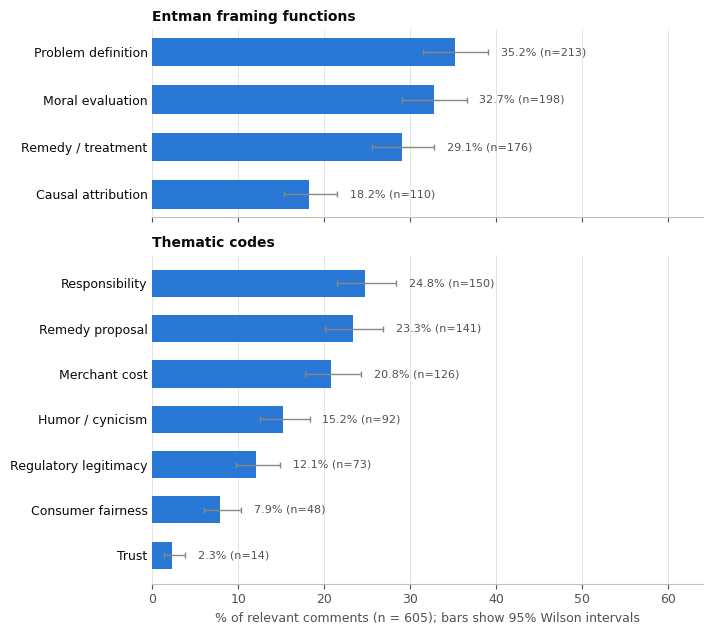


GAMBAR 3: MATRIKS KO-OKURENSI & JACCARD HEATMAP


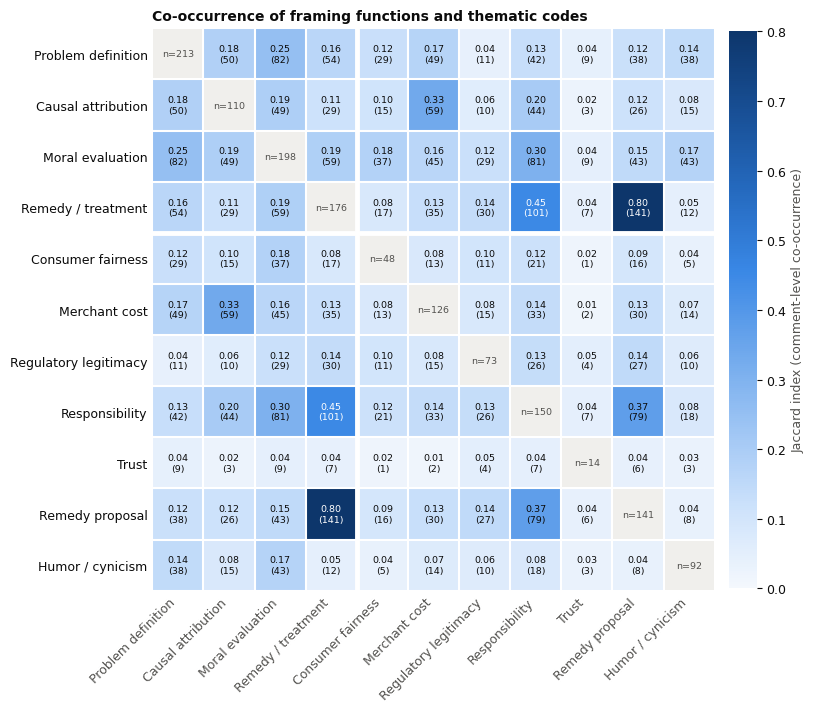


GAMBAR 4: PREVALENSI FRAME BERDASARKAN KONTEKS VIDEO


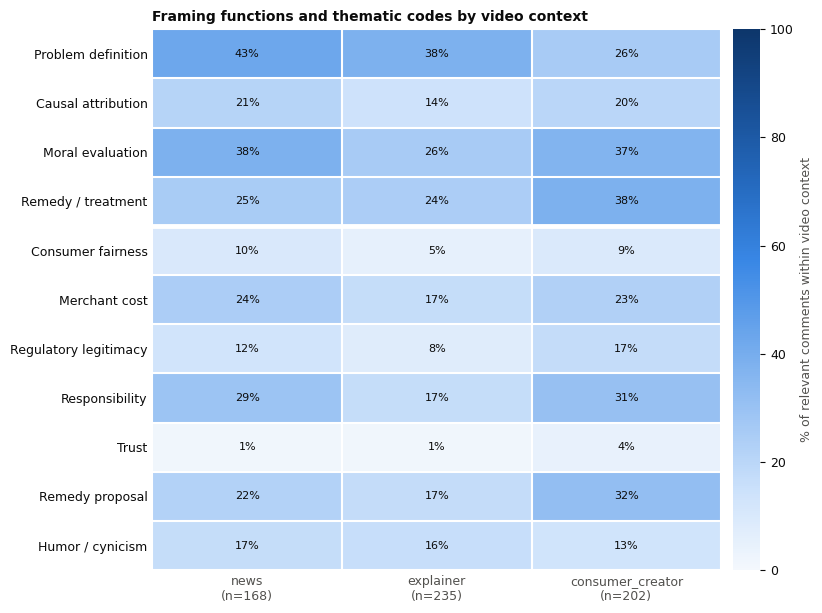


SEMUA TABEL & GAMBAR BERHASIL DISIMPAN DI GOOGLE DRIVE:
1. Tabel CSV: /content/drive/MyDrive/QRIS/qris-surcharge-framing/outputs/tables
2. Gambar (PNG & PDF): /content/drive/MyDrive/QRIS/qris-surcharge-framing/outputs/figures


In [15]:
# 12. Pembuatan Figure Publikasi Lengkap (Fig 2, Fig 3, Fig 4)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Palet visual naskah jurnal
INK, INK_SECONDARY, MUTED = "#0b0b0b", "#52514e", "#898781"
GRIDLINE, BASELINE, SERIES_COLOR = "#e1e0d9", "#c3c2b7", "#2a78d6"
NEUTRAL_CELL, SURFACE = "#f0efec", "#ffffff"
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    "sequential_blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
STYLE = {
    "font.family": "sans-serif", "font.size": 9, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK, "xtick.color": INK_SECONDARY,
    "ytick.color": INK, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE
}

def style_heatmap(ax, n_rows, n_cols):
    ax.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=1.5)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values(): s.set_visible(False)

# ==========================================
# 1. FIG 2: HORIZONTAL BAR PLOT PREVALENSI FRAME
# ==========================================
panels = [("entman", "Entman framing functions"), ("thematic", "Thematic codes")]
sizes = [max(1, int((df_prevalence["code_type"] == k).sum())) for k, _ in panels]
x_max = float(df_prevalence["ci95_high"].max()) + 25.0

with plt.rc_context(STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(7.2, 0.42 * sum(sizes) + 1.8), sharex=True, gridspec_kw={"height_ratios": sizes})
    for ax, (kind, title) in zip(axes, panels):
        part = df_prevalence[df_prevalence["code_type"] == kind].sort_values("pct", ascending=True)
        pos = np.arange(len(part))
        ax.barh(pos, part["pct"], height=0.6, color=SERIES_COLOR, zorder=2)
        errors = [part["pct"] - part["ci95_low"], part["ci95_high"] - part["pct"]]
        ax.errorbar(part["pct"], pos, xerr=errors, fmt="none", ecolor=MUTED, elinewidth=1, capsize=2, zorder=3)
        for p, (pct, high, n) in zip(pos, part[["pct", "ci95_high", "n"]].itertuples(index=False)):
            ax.text(high + 1.5, p, f"{pct:.1f}% (n={n})", va="center", fontsize=8, color=INK_SECONDARY)
        ax.set_yticks(pos, part["label"].tolist())
        ax.set_title(title, loc="left", fontsize=10, fontweight="bold")
        ax.grid(axis="x", color=GRIDLINE, linewidth=0.6, zorder=0)
        ax.set_axisbelow(True)
        for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
        ax.tick_params(axis="y", length=0)
    axes[-1].set_xlim(0, x_max)
    axes[-1].set_xlabel(f"% of relevant comments (n = {n_total}); bars show 95% Wilson intervals")
    fig.tight_layout()
    fig.savefig(os.path.join(figures_dir, "fig_code_prevalence.png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(figures_dir, "fig_code_prevalence.pdf"), bbox_inches="tight")
    print("GAMBAR 2: PREVALENSI FRAME & WILSON CI 95%")
    plt.show()

# ==========================================
# 2. FIG 3: HEATMAP MATRIKS KO-OKURENSI (JACCARD INDEX)
# ==========================================
matrix = fc_rel[ALL_BINARY_CODES].to_numpy(dtype=int)
size = len(ALL_BINARY_CODES)
jaccard = np.full((size, size), np.nan)
counts = np.zeros((size, size), dtype=int)

for i in range(size):
    for j in range(size):
        both = int(((matrix[:, i] == 1) & (matrix[:, j] == 1)).sum())
        union = int(((matrix[:, i] == 1) | (matrix[:, j] == 1)).sum())
        counts[i, j] = both
        if i != j and union > 0:
            jaccard[i, j] = round(both / union, 4)

v_max = float(np.nanmax(jaccard))
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(8.5, 7.2))
    cmap = SEQUENTIAL_BLUE.with_extremes(bad=NEUTRAL_CELL)
    im = ax.imshow(np.ma.masked_invalid(jaccard), cmap=cmap, vmin=0.0, vmax=v_max)
    for i in range(size):
        for j in range(size):
            if i == j:
                ax.text(j, i, f"n={counts[i, j]}", ha="center", va="center", fontsize=6.8, color=INK_SECONDARY)
            elif np.isfinite(jaccard[i, j]):
                col = SURFACE if jaccard[i, j] > 0.55 * v_max else INK
                ax.text(j, i, f"{jaccard[i, j]:.2f}\n({counts[i, j]})", ha="center", va="center", fontsize=6.8, color=col)
    tick_lbls = [LABELS_DICT.get(c, c) for c in ALL_BINARY_CODES]
    ax.set_xticks(range(size), tick_lbls, rotation=45, ha="right")
    ax.set_yticks(range(size), tick_lbls)
    style_heatmap(ax, size, size)
    split = len(ENTMAN_FUNCS) - 0.5
    ax.axhline(split, color=SURFACE, linewidth=3.5)
    ax.axvline(split, color=SURFACE, linewidth=3.5)
    cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cbar.set_label("Jaccard index (comment-level co-occurrence)", color=INK_SECONDARY)
    cbar.outline.set_visible(False)
    ax.set_title("Co-occurrence of framing functions and thematic codes", loc="left", fontsize=10, fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(figures_dir, "fig_code_cooccurrence_heatmap.png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(figures_dir, "fig_code_cooccurrence_heatmap.pdf"), bbox_inches="tight")
    print("\nGAMBAR 3: MATRIKS KO-OKURENSI & JACCARD HEATMAP")
    plt.show()

# ==========================================
# 3. FIG 4: HEATMAP PREVALENSI BERDASARKAN KONTEKS VIDEO
# ==========================================
n_contexts = len(contexts)
values_ctx = np.zeros((size, n_contexts))
ctx_counts = {ctx: len(fc_rel[fc_rel['video_context'] == ctx]) for ctx in contexts}

for r_idx, code in enumerate(ALL_BINARY_CODES):
    for c_idx, ctx in enumerate(contexts):
        sub = fc_rel[fc_rel['video_context'] == ctx]
        values_ctx[r_idx, c_idx] = round(100.0 * sub[code].sum() / len(sub), 1) if len(sub) else 0.0

with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(1.35 * n_contexts + 4.2, 6.2))
    im = ax.imshow(values_ctx, cmap=SEQUENTIAL_BLUE.with_extremes(bad=NEUTRAL_CELL), vmin=0.0, vmax=100.0, aspect="auto")
    for i in range(size):
        for j in range(n_contexts):
            col = SURFACE if values_ctx[i, j] > 55.0 else INK
            ax.text(j, i, f"{values_ctx[i, j]:.0f}%", ha="center", va="center", fontsize=8, color=col)
    ax.set_xticks(range(n_contexts), [f"{c}\n(n={ctx_counts[c]})" for c in contexts])
    ax.set_yticks(range(size), [LABELS_DICT.get(c, c) for c in ALL_BINARY_CODES])
    style_heatmap(ax, size, n_contexts)
    ax.axhline(len(ENTMAN_FUNCS) - 0.5, color=SURFACE, linewidth=3.5)
    cbar = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
    cbar.set_label("% of relevant comments within video context", color=INK_SECONDARY)
    cbar.outline.set_visible(False)
    ax.set_title("Framing functions and thematic codes by video context", loc="left", fontsize=10, fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(figures_dir, "fig_code_by_context.png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(figures_dir, "fig_code_by_context.pdf"), bbox_inches="tight")
    print("\nGAMBAR 4: PREVALENSI FRAME BERDASARKAN KONTEKS VIDEO")
    plt.show()

print("\n" + "=" * 70)
print(f"SEMUA TABEL & GAMBAR BERHASIL DISIMPAN DI GOOGLE DRIVE:")
print(f"1. Tabel CSV: {tables_dir}")
print(f"2. Gambar (PNG & PDF): {figures_dir}")
print("=" * 70)